# DIRECT-II paper — results

- Part A: finished ml4fmri runs (vanilla models and DGCNN), summarised for the paper
- Part B: transfer experiments, added once the run plan is agreed
- Tables and figures go to `results/`

In [14]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA = "../02_on_MDD_data/data"  # finished cvbench runs
OUT = "results"                  # tables and figures for the paper
os.makedirs(OUT, exist_ok=True)


def load(run, models=None, **tags):
    """Test scores of one finished cvbench run, one row per model and fold."""
    path = os.path.join(DATA, run)
    res = pd.read_csv(f"{path}/cvbench_test.csv")
    counts = json.load(open(f"{path}/cvbench_meta.json"))["data"]["class_counts"]
    if models:
        res = res[res["model"].isin(models)]
    return res.assign(classes="/".join(map(str, counts.values())), **tags)


def summary(res, by):
    """Mean ± SD over folds of test AUC and balanced accuracy, best AUC first."""
    stats = res.groupby(by)[["test_auc", "test_balanced_accuracy"]].agg(["mean", "std"])
    stats = stats.sort_values(("test_auc", "mean"), ascending=False)
    return pd.DataFrame({
        name: stats[col]["mean"].map("{:.3f}".format) + " ± " + stats[col]["std"].map("{:.3f}".format)
        for name, col in (("AUC", "test_auc"), ("balanced acc", "test_balanced_accuracy"))
    })

## MDD vs HC

- 1,944 subjects (1,113 MDD / 831 HC); every model uses the same 10 folds
- ICA-53: the 13 vanilla ml4fmri models and DGCNN (`../02_on_MDD_data/models/DGCNN.py`)
- ICA-105: meanMLP and LR, the only vanilla models run on it

In [15]:
mdd = pd.concat([
    load("mdd_vs_hc", data="ICA-53"),
    load("mdd_vs_hc_dgcnn_local", data="ICA-53"),
    load("mdd_vs_hc_with_Brad_models_105", models=["meanMLP", "LR"], data="ICA-105"),
], ignore_index=True)

table = summary(mdd, ["data", "model"])
table.to_csv(f"{OUT}/mdd_vs_hc.csv")
table

AUC   balanced acc
data    model                                        
ICA-53  meanMLP          0.741 ± 0.046  0.677 ± 0.033
ICA-105 meanMLP          0.735 ± 0.051  0.674 ± 0.052
        LR               0.724 ± 0.049  0.648 ± 0.037
ICA-53  BolT             0.724 ± 0.043  0.655 ± 0.033
        Glacier          0.722 ± 0.048  0.647 ± 0.056
        LR               0.709 ± 0.036  0.650 ± 0.036
        BNT              0.703 ± 0.035  0.651 ± 0.037
        DICE             0.703 ± 0.027  0.617 ± 0.046
        BrainNetCNN      0.701 ± 0.040  0.642 ± 0.045
        meanLSTM         0.699 ± 0.045  0.637 ± 0.040
        FBNetGen         0.686 ± 0.037  0.630 ± 0.047
        DGCNN            0.645 ± 0.048  0.600 ± 0.040
        DGCNNRaw         0.630 ± 0.038  0.574 ± 0.038
        MILC             0.626 ± 0.052  0.575 ± 0.036
        LSTM             0.580 ± 0.071  0.551 ± 0.038
        meanTransformer  0.577 ± 0.033  0.534 ± 0.034
        Transformer      0.560 ± 0.044  0.531 ± 0.050

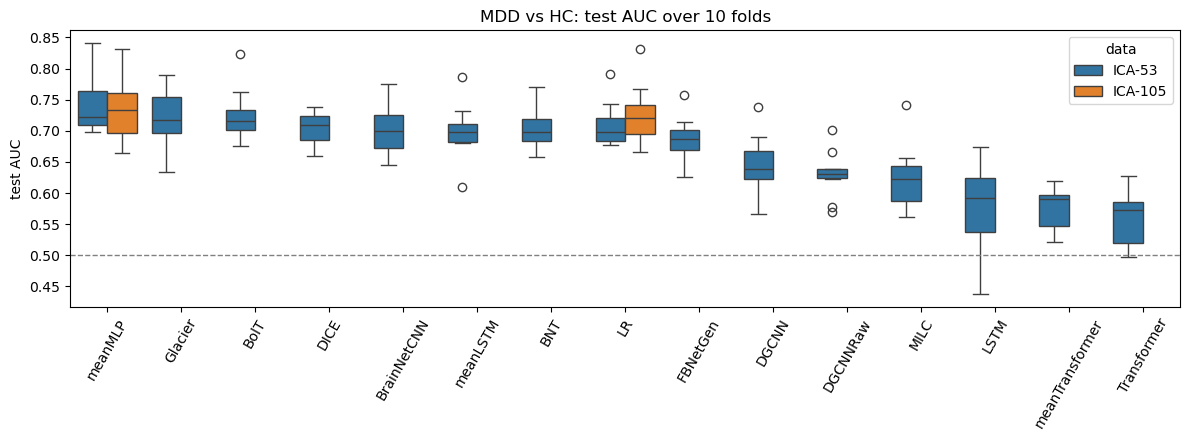

In [16]:
# models ordered by their ICA-53 median AUC
ica53 = mdd[mdd["data"] == "ICA-53"]
order = ica53.groupby("model")["test_auc"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=mdd, x="model", y="test_auc", hue="data", order=order, ax=ax)
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set(title="MDD vs HC: test AUC over 10 folds", xlabel="", ylabel="test AUC")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
fig.savefig(f"{OUT}/mdd_vs_hc.png", dpi=150)

## Suicidality (HAMD item 3)

- HAMD-3 scores (0–4) split into low vs high six ways, e.g. `01|234` = 0–1 vs 2–4
- `0|1|2|3|4` (multiclass): all five scores as classes; its AUC is the mean of the one-vs-rest AUCs
- Two cohorts:
  - patients only
  - patients plus HC, with HC scored 0
- meanMLP, BolT, BNT and LR (no BolT for 5 classes); each contrast has its own 10 folds
- Figures: patients + HC only

In [17]:
CONFIGS = {"suicidality": "patients", "suicidality_withHC": "patients + HC"}
CONTRASTS = ["0|1234", "01|234", "012|34", "0123|4", "01|34", "0|4", "0|1|2|3|4"]


def folder(run, contrast):
    """Binary contrasts ran on the cluster (folders use v for |); the 5-class runs are local ones."""
    return f"{run}_local/multiclass" if contrast == "0|1|2|3|4" else f"{run}/hamd3_{contrast.replace('|', 'v')}"


hamd3 = pd.concat([
    load(folder(run, contrast), config=config, contrast=contrast)
    for run, config in CONFIGS.items() for contrast in CONTRASTS
], ignore_index=True)

# mean test AUC per contrast and model; classes = subjects per class, low to high score
table = hamd3.pivot_table(index=["config", "contrast", "classes"], columns="model",
                          values="test_auc", sort=False).round(3)
table.to_csv(f"{OUT}/hamd3.csv")
table

model                                       meanMLP   BolT    BNT     LR
config        contrast  classes                                         
patients      0|1234    217/396               0.555  0.582  0.546  0.521
              01|234    383/230               0.687  0.633  0.670  0.637
              012|34    467/146               0.757  0.727  0.724  0.699
              0123|4    570/43                0.727  0.641  0.666  0.754
              01|34     383/146               0.761  0.702  0.724  0.712
              0|4       217/43                0.783  0.680  0.674  0.743
              0|1|2|3|4 217/166/84/103/43     0.646    NaN  0.586  0.597
patients + HC 0|1234    1048/396              0.709  0.679  0.686  0.670
              01|234    1214/230              0.735  0.722  0.712  0.697
              012|34    1298/146              0.789  0.738  0.721  0.755
              0123|4    1401/43               0.754  0.643  0.716  0.766
              01|34     1214/146              0.785  0.745  0.761  0.770
              0|4       1048/43               0.788  0.666  0.693  0.780
              0|1|2|3|4 1048/166/84/103/43    0.725    NaN  0.650  0.687

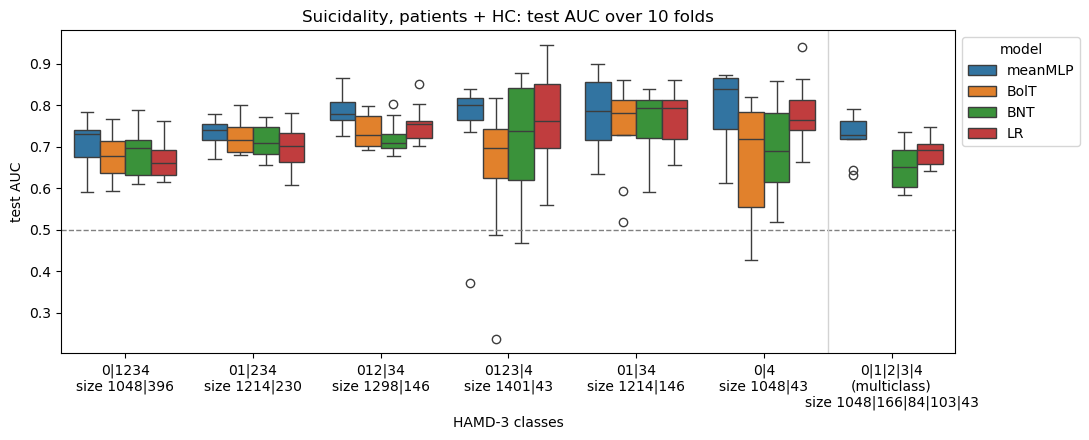

In [18]:
# patients + HC only; the vertical line sets the 5-class contrast apart
withhc = hamd3[hamd3["config"] == "patients + HC"]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=withhc, x="contrast", y="test_auc", hue="model", order=CONTRASTS, ax=ax)
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.axvline(len(CONTRASTS) - 1.5, c="lightgray", lw=1)
sizes = withhc.groupby("contrast")["classes"].first().str.replace("/", "|")  # subjects per class
labels = [f"{c}\n(multiclass)" if c == CONTRASTS[-1] else c for c in CONTRASTS]
ax.set_xticks(range(len(CONTRASTS)), [f"{label}\nsize {sizes[c]}" for label, c in zip(labels, CONTRASTS)])
ax.set(title="Suicidality, patients + HC: test AUC over 10 folds", xlabel="HAMD-3 classes", ylabel="test AUC")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(f"{OUT}/hamd3.png", dpi=150)

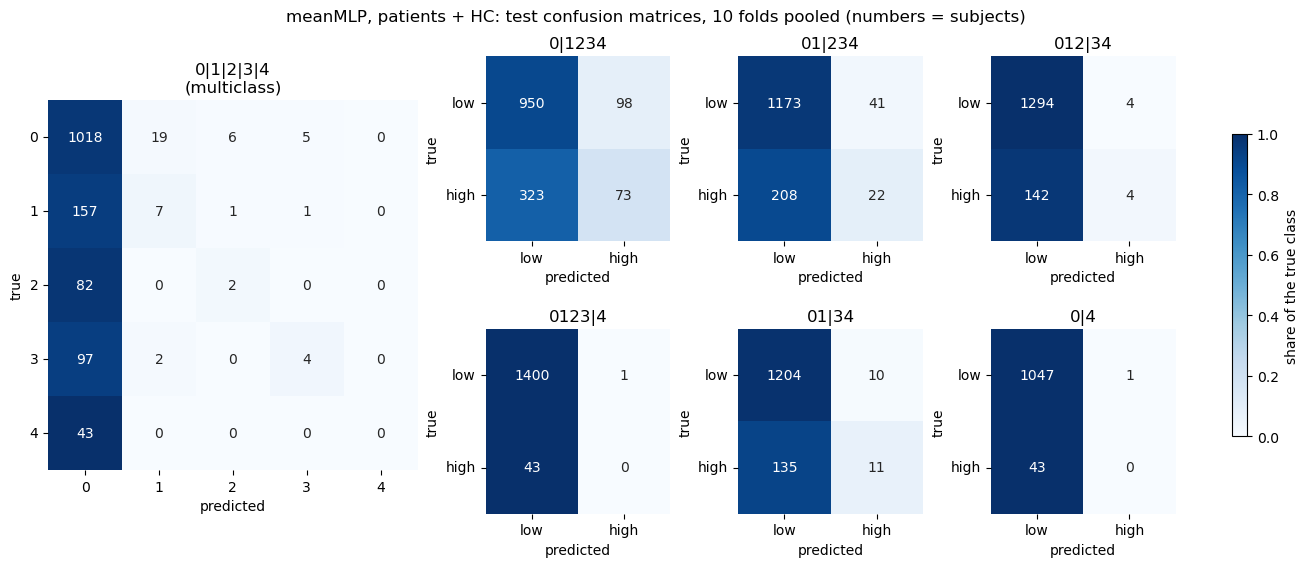

In [19]:
# one model's test confusion matrices, patients + HC; folds pooled, so each subject counts once
MODEL = "meanMLP"

five, binary = CONTRASTS[-1], CONTRASTS[:-1]
fig, axes = plt.subplot_mosaic([[five, five, *binary[:3]], [five, five, *binary[3:]]],
                               figsize=(13, 5.6), layout="constrained")
for contrast, ax in axes.items():
    runs = withhc[(withhc["model"] == MODEL) & (withhc["contrast"] == contrast)]
    k = 5 if contrast == five else 2
    cm = np.array([[runs[f"test_cm_true{i}_pred{j}"].sum() for j in range(k)] for i in range(k)]).astype(int)
    ticks = list(range(k)) if k > 2 else ["low", "high"]
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", vmin=0, vmax=1, cmap="Blues",
                cbar=False, square=True, xticklabels=ticks, yticklabels=ticks, ax=ax)
    ax.set(title=f"{contrast}\n(multiclass)" if contrast == five else contrast, xlabel="predicted", ylabel="true")
    ax.tick_params(axis="y", rotation=0)

fig.colorbar(ax.collections[0], ax=list(axes.values()), shrink=0.6, label="share of the true class")
fig.suptitle(f"{MODEL}, patients + HC: test confusion matrices, 10 folds pooled (numbers = subjects)")
fig.savefig(f"{OUT}/hamd3_confusion.png", dpi=150)

## Part B: transfer

Two tasks, with no subject in both:
- **Pretraining task**: train meanMLP from scratch
  - MDD vs HC, or sex as a control
  - 770 subjects (427 MDD / 343 HC)
- **Target task**: start from the pretrained model and retrain all of it, or score it as it is (frozen); compare with training from scratch
  - suicidality (HAMD-3 01|234), on medication, first episode, sex
  - the 612 patients with HAMD-3

Pretraining subjects, two configs of the same size:
- sites controlled: the 4 sites with no HAMD-3 patients
- sites shared: drawn from everyone outside the target half (below), so the target task's sites appear in pretraining

Target task splits:
- the 612 patients are split into two halves with the same site mix
- round 1: half 1 is the target task (10-fold CV inside it); half 2 can be used for pretraining
- round 2 swaps the halves, so every patient is tested once
- why halves: without them, only 74 MDD patients from the target sites would be left for sites-shared pretraining
- every start (trained from scratch, pretrained or frozen) is scored on the same 10 test folds

In [20]:
import torch
from ml4fmri.models.meanMLP import meanMLP
from ml4fmri.utils import _seed_everything
from scipy import stats
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED, N_FOLDS = 42, 10
# what a pretrained start keeps from pretraining: "reset" = encoder (output layer re-initialised at random),
# "zero" = encoder (output layer zeroed), "keep" = encoder + output layer, "frozen" = as "keep", not retrained
HEADS = ["reset", "keep", "frozen"]

# the 1,944 subjects of the MDD vs HC benchmark, and their labels (NaN = missing)
npz = np.load(f"{DATA}/mdd_ica53_tc_superclean.npz", allow_pickle=True)
full = npz["full"].astype(bool)
X = npz["ica53_tc"][full].astype(np.float32)
meta = pd.read_csv(f"{DATA}/mdd_master_full.csv", low_memory=False).set_index("id").loc[npz["id"][full]]
col = lambda name: pd.to_numeric(meta[name], errors="coerce").to_numpy()
hamd3_score = col("HAMD3")

labels = {
    "MDD vs HC": col("Diagnosis"),
    "sex": col("Sex") - 1,  # 0 male, 1 female
    "suicidality (HAMD-3 01|234)": np.where(np.isnan(hamd3_score), np.nan, hamd3_score >= 2),
    "first episode": col("FirstEpisode"),
    "on medication": col("OnMedication"),
}
site, is_mdd = meta["site"].to_numpy(), labels["MDD vs HC"] == 1

In [21]:
# target task pool: patients with HAMD-3, in two halves with the same site mix
h = np.flatnonzero(~np.isnan(hamd3_score))
halves = [h[part] for _, part in StratifiedKFold(2, shuffle=True, random_state=SEED).split(h, site[h])]

# sites-controlled pretraining: the sites with no HAMD-3 patients
controlled = np.flatnonzero(~np.isin(site, site[h]))


def source_subjects(config, half):
    """Pretraining subjects for one config and round; none of them is in this round's half."""
    if config == "sites controlled":
        return controlled
    pool = np.setdiff1d(np.arange(len(X)), half)
    rng = np.random.default_rng(SEED)
    pick = lambda group, n: rng.choice(pool[group[pool]], n, replace=False)  # same size as sites controlled
    return np.concatenate([pick(is_mdd, is_mdd[controlled].sum()), pick(~is_mdd, (~is_mdd[controlled]).sum())])


print(f"target task halves: {[len(half) for half in halves]} patients")
print(f"sites-controlled pretraining: {len(controlled)} subjects ({is_mdd[controlled].sum()} MDD) from {sorted(set(site[controlled]))}")

target task halves: [306, 306] patients
sites-controlled pretraining: 770 subjects (427 MDD) from ['IS001', 'IS009', 'IS015', 'IS023']


In [22]:
def run(train, test, y, init=None, head=None, seed=SEED):
    """Train meanMLP on `train` (20% held out for early stopping) and score it on `test`.

    `init` is a pretrained state_dict to start from, and `head` one of HEADS. With `test=None`
    the score is on the held-out 20%, as for pretraining.
    """
    _seed_everything(seed)
    tr, val = train_test_split(train, test_size=0.2, stratify=y[train], random_state=seed)
    test = val if test is None else test
    loaders = [meanMLP.prepare_dataloader(X[i], y[i].astype(int), shuffle=shuffle)
               for i, shuffle in ((tr, True), (val, False), (test, False))]

    model = meanMLP(input_size=X.shape[2], output_size=2)
    if init is not None:
        model.load_state_dict(init)
        out = model.mlp[-1]
        if head == "zero":
            torch.nn.init.zeros_(out.weight)
            torch.nn.init.zeros_(out.bias)
        elif head == "reset":
            out.reset_parameters()

    _, log, _ = model.train_model(*loaders, epochs=0 if head == "frozen" else 200)  # 0 epochs: score only
    return model, log.iloc[0]

In [23]:
CONFIGS = ["sites controlled", "sites shared"]
SOURCES = ["MDD vs HC", "sex"]
TARGETS = ["suicidality (HAMD-3 01|234)", "first episode", "on medication", "sex"]
TAG = "_".join(HEADS)
CACHE = f"{OUT}/transfer_{TAG}.csv"  # reused if present; delete it to retrain


def run_all():
    """Per round: the pretrained models, then every target task from scratch and from each of them."""
    rows = []
    for r, half in enumerate(halves):
        pretrained = {}
        for config in CONFIGS:
            pre = source_subjects(config, half)
            assert not np.intersect1d(pre, half).size  # no subject in both tasks
            for source in SOURCES:
                model, log = run(pre, None, labels[source])
                pretrained[f"{source}, {config}"] = model.state_dict()
                rows.append(dict(task="pretraining", target=source, start=config, round=r, auc=log["test_auc"]))

        # same folds for scratch and every pretrained start
        starts = [("scratch", None, "-")] + [
            (name, state, head) for name, state in pretrained.items() for head in HEADS]
        for target in TARGETS:
            y = labels[target]
            tgt = half[~np.isnan(y[half])]
            folds = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(tgt, y[tgt])
            for k, (tr, te) in enumerate(folds):
                for start, state, head in starts:
                    _, log = run(tgt[tr], tgt[te], y, init=state, head=head, seed=SEED + k)
                    rows.append(dict(task="target", target=target, start=start, head=head, round=r, fold=k,
                                     auc=log["test_auc"], bacc=log["test_balanced_accuracy"], n=len(tgt)))
    return pd.DataFrame(rows)


transfer = pd.read_csv(CACHE) if os.path.exists(CACHE) else run_all()
transfer.to_csv(CACHE, index=False)

# sanity check: each pretrained model scored on its own task
check = transfer[transfer["task"] == "pretraining"].pivot_table(index="target", columns="start", values="auc")
check.rename_axis(index="pretraining task", columns="pretraining subjects").style.format(precision=3).set_caption(
    "Pretrained models on their own task: validation AUC (one 80/20 split, no CV), mean of the 2 rounds")

pretraining subjects,sites controlled,sites shared
pretraining task,,
MDD vs HC,0.677,0.753
sex,0.893,0.899


In [24]:
# what each start keeps from pretraining, as named in the table and plot
WEIGHTS = {"-": "none", "reset": "encoder", "zero": "encoder, zero head",
           "keep": "encoder + head", "frozen": "encoder + head, frozen"}
SCRATCH = "trained\n from scratch"
res = transfer[transfer["task"] == "target"]
res = res.assign(start=res["start"].replace("scratch", SCRATCH), weights=res["head"].map(WEIGHTS))

# mean AUC per start, and its paired difference from scratch over the 2 x 10 folds
keys = ["target", "round", "fold"]
scratch = res[res["start"] == SCRATCH].set_index(keys)["auc"]

rows = []
for (target, start, weights), g in res.groupby(["target", "start", "weights"], sort=False):
    d = g.set_index(keys)["auc"] - scratch.loc[target]
    p = None
    if start != SCRATCH:
        t = d.mean() / np.sqrt((1 / len(d) + 1 / (N_FOLDS - 1)) * d.var())  # Nadeau-Bengio correction
        p = round(2 * stats.t.sf(abs(t), len(d) - 1), 3)
    rows.append(dict(target=target, start=start, weights=weights, n=int(g.groupby("round")["n"].first().sum()),
                     auc=f"{g['auc'].mean():.3f} ± {g['auc'].std():.3f}", delta=round(d.mean(), 3),
                     wins=f"{(d > 0).sum()}/{len(d)}", p=p))

table = pd.DataFrame(rows)
table.to_csv(f"{OUT}/transfer_summary_{TAG}.csv", index=False)
table

,target,start,weights,n,auc,delta,wins,p
0,suicidality (HAMD-3 01|234),trained\n from scratch,none,612,0.653 ± 0.081,0.000,0/20,NaN
1,suicidality (HAMD-3 01|234),"MDD vs HC, sites controlled",encoder,612,0.654 ± 0.077,0.000,9/20,0.991
2,suicidality (HAMD-3 01|234),"MDD vs HC, sites controlled",encoder + head,612,0.666 ± 0.103,0.013,12/20,0.791
3,suicidality (HAMD-3 01|234),"MDD vs HC, sites controlled","encoder + head, frozen",612,0.563 ± 0.108,-0.090,5/20,0.130
4,suicidality (HAMD-3 01|234),"sex, sites controlled",encoder,612,0.666 ± 0.088,0.012,12/20,0.446
5,suicidality (HAMD-3 01|234),"sex, sites controlled",encoder + head,612,0.655 ± 0.103,0.001,9/20,0.974
6,suicidality (HAMD-3 01|234),"sex, sites controlled","encoder + head, frozen",612,0.535 ± 0.105,-0.118,3/20,0.021
7,suicidality (HAMD-3 01|234),"MDD vs HC, sites shared",encoder,612,0.664 ± 0.076,0.010,11/20,0.609
8,suicidality (HAMD-3 01|234),"MDD vs HC, sites shared",encoder + head,612,0.648 ± 0.103,-0.005,13/20,0.915
9,suicidality (HAMD-3 01|234),"MDD vs HC, sites shared","encoder + head, frozen",612,0.573 ± 0.110,-0.080,8/20,0.204


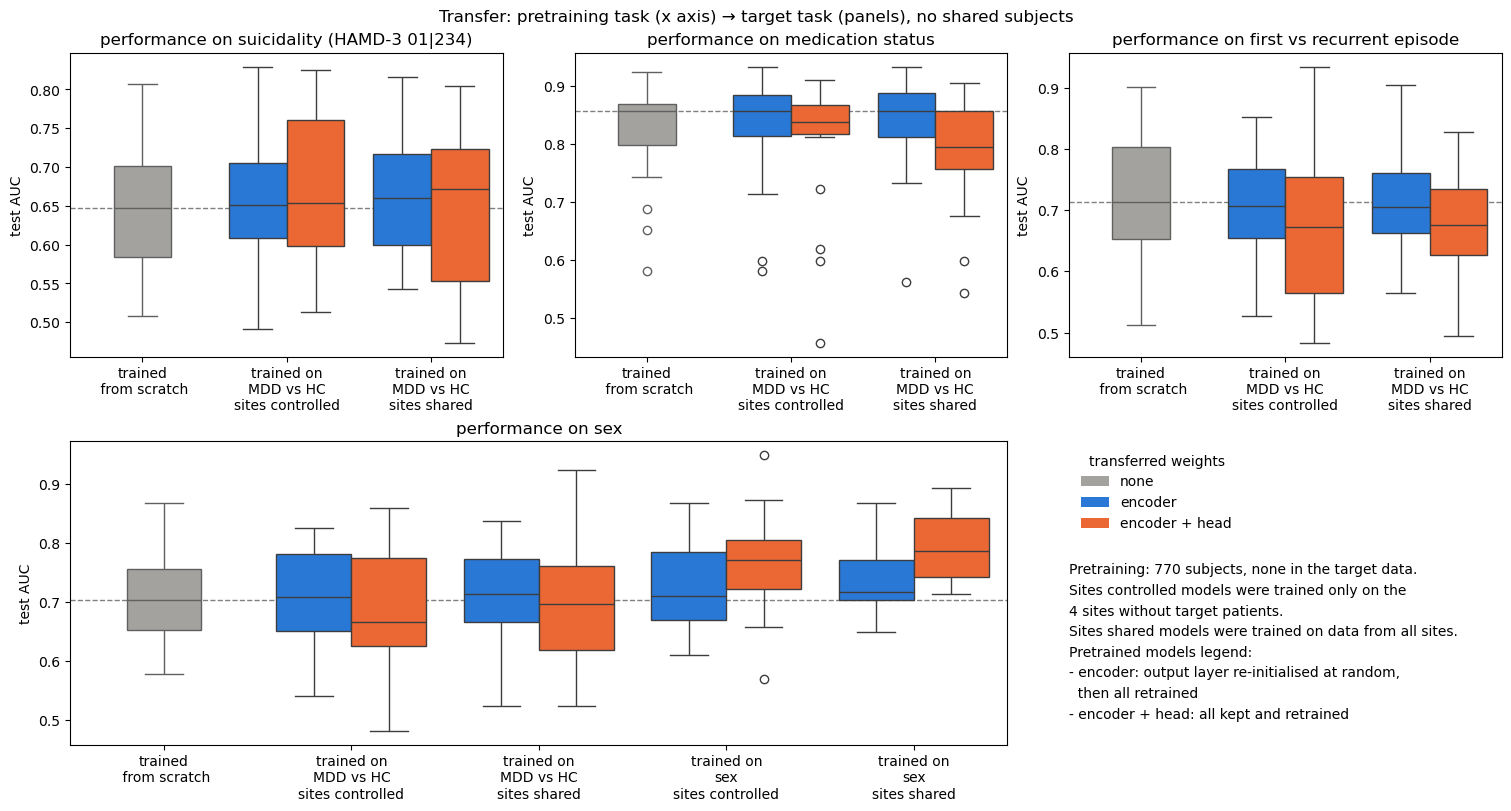

In [25]:
# top: MDD vs HC pretraining on the clinical targets; bottom: sex, with sex pretraining as the control
SHOWN = ["reset", "keep"]  # the frozen starts stay in the table above
CLINICAL = ["suicidality (HAMD-3 01|234)", "on medication", "first episode"]
TITLES = {"on medication": "medication status", "first episode": "first vs recurrent episode"}
hue_order = [WEIGHTS[head] for head in SHOWN]
palette = dict(zip(WEIGHTS.values(), ["#a3a29e", "#2a78d6", "#1baf7a", "#eb6834", "#6250d6"]))

fig, axes = plt.subplot_mosaic([CLINICAL, ["sex", "sex", "notes"]], figsize=(15, 8), layout="constrained")
for target in CLINICAL + ["sex"]:
    sources = SOURCES if target == "sex" else ["MDD vs HC"]
    order = [SCRATCH] + [f"{source}, {config}" for source in sources for config in CONFIGS]
    g = res[(res["target"] == target) & res["start"].isin(order) & res["head"].isin(["-"] + SHOWN)]
    from_scratch = g[g["start"] == SCRATCH]

    ax = axes[target]
    sns.boxplot(data=from_scratch, x="start", y="auc", order=order, color=palette["none"],
                width=0.8 / len(SHOWN), saturation=1, ax=ax)
    sns.boxplot(data=g[g["start"] != SCRATCH], x="start", y="auc", order=order, hue="weights",
                hue_order=hue_order, palette=palette, saturation=1, legend=False, ax=ax)
    ax.axhline(from_scratch["auc"].median(), ls="--", c="gray", lw=1, zorder=0)
    ax.set_xticks(range(len(order)), [start if start == SCRATCH else "trained on\n{}\n{}".format(*start.split(", "))
                                      for start in order])
    ax.set(title=f"performance on {TITLES.get(target, target)}", xlabel="", ylabel="test AUC")

# in-figure legend and the setting in short
notes = axes["notes"]
notes.axis("off")
notes.legend([plt.Rectangle((0, 0), 1, 1, fc=palette[w]) for w in ["none"] + hue_order], ["none"] + hue_order,
             title="transferred weights", loc="upper left", frameon=False)
notes.text(0, 0.6, """Pretraining: 770 subjects, none in the target data.
Sites controlled models were trained only on the
4 sites without target patients.
Sites shared models were trained on data from all sites.
Pretrained models legend:
- encoder: output layer re-initialised at random,
  then all retrained
- encoder + head: all kept and retrained""", va="top", transform=notes.transAxes, linespacing=1.6)
fig.suptitle("Transfer: pretraining task (x axis) → target task (panels), no shared subjects")
fig.savefig(f"{OUT}/transfer_{TAG}.png", dpi=150)